# T47D CDK variants — volcano plots, variant vs matched NT control

Standalone notebook that draws the variant-vs-control volcano grid from the T47D CDK2/4/6 variant RNA-seq (DESeq2 results).

**Figure** (saved to `figures/volcano_variant_vs_control.svg` / `.png`): 2 rows × 4 columns.
- **Top row — DMSO**, **bottom row — Palbociclib**; each panel is one variant vs its matched non-targeting control in that arm (CDK2 S261G and CDK4 I51V vs ABE NT; CDK6 G53S_M54I and CDK6 R44C_R46W vs CBE NT). Display names are set in `DISPLAY_NAMES`; data files keep the short names (`CDK6_G53S`, `CDK6_R46W`).
- Red / blue = significantly up / down (padj < `PADJ_THRESH` and |log2FC| > `LFC_THRESH`); grey = not significant. Dashed lines mark the thresholds.
- Cell-proliferation genes are highlighted as one group (purple): the union of the Hallmark **E2F Targets** and **G2-M Checkpoint** sets (`PROLIF_SETS`). The `N_LABELS` most significant of these genes per panel are labelled.
- x-axis fixed at ±`X_LIM`; y-axis shared across all 8 panels.

**To run**
- Keep this notebook next to the `data/` folder, which holds:
  - `deseq2_results/<variant>_vs_<control>_<veh|palbo>.csv` — DESeq2 results (columns: `gene_id, baseMean, log2FoldChange, lfcSE, stat, pvalue, padj, gene_name`); `veh` = DMSO.
  - `hallmark_gene_sets_cache.json` — MSigDB Hallmark gene sets (E2F Targets, G2-M Checkpoint, …).
- Python 3 with `pandas`, `numpy`, `matplotlib`; `adjustText` is optional but recommended (`pip install adjustText`) so gene labels don't overlap.
- Run all cells top to bottom.

In [1]:
# ── Imports & style ──────────────────────────────────────────────────────────
%matplotlib inline
import json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from adjustText import adjust_text
    HAS_ADJUSTTEXT = True
except ImportError:
    HAS_ADJUSTTEXT = False
    print('adjustText not installed — gene labels may overlap (pip install adjustText)')

# Helvetica if installed, otherwise the closest available sans-serif
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial', 'Nimbus Sans', 'Liberation Sans', 'DejaVu Sans']
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.rcParams['svg.fonttype'] = 'none'     # keep SVG text editable in Illustrator
plt.rcParams['figure.dpi'] = 110

In [2]:
# ── Paths & settings ─────────────────────────────────────────────────────────
BASE           = Path.cwd()
DESEQ2_DIR     = BASE / 'data' / 'deseq2_results'
HALLMARK_CACHE = BASE / 'data' / 'hallmark_gene_sets_cache.json'
FIG_DIR        = BASE / 'figures'
FIG_DIR.mkdir(exist_ok=True)

# Variants shown (left → right) and their matched non-targeting control
CONTROL_FOR = {'CDK2_S261G': 'ABE_NT', 'CDK4_I51V': 'ABE_NT',
               'CDK6_G53S':  'CBE_NT', 'CDK6_R46W': 'CBE_NT'}
ROWS = [('veh', 'DMSO'), ('palbo', 'Palbociclib')]     # (file suffix, row label), top → bottom

LFC_THRESH  = 1.0
PADJ_THRESH = 0.05
X_LIM       = 6      # fixed log2FC axis range
N_LABELS    = 8      # most-significant cell-cycle genes labelled per panel

# Colours
UP_COLOR, DOWN_COLOR, NS_COLOR, THRESH_COLOR = '#d6604d', '#4393c3', '#d0d0d0', '#999999'

# Font sizes
FS_ROW    = 20   # DMSO / Palbociclib row labels
FS_TITLE  = 15   # panel titles
FS_AXIS   = 14   # axis labels
FS_TICK   = 12   # tick labels
FS_GENE   = 10   # gene labels
FS_LEGEND = 11   # legends

# Cell-proliferation genes = union of these Hallmark sets, highlighted as ONE group
PROLIF_SETS  = ['E2F Targets', 'G2-M Checkpoint']
PROLIF_LABEL = 'Cell proliferation\n(Hallmark E2F + G2-M)'
PROLIF_COLOR = '#7B3294'   # purple, distinct from the red/blue DE colours
_hm = json.loads(HALLMARK_CACHE.read_text())
PROLIF_GENES = set().union(*(_hm[s] for s in PROLIF_SETS))
print(f'{len(PROLIF_GENES)} cell-proliferation genes ({" + ".join(PROLIF_SETS)})')


# Cell-line names shown in the panel titles (genotypes not listed here use pretty_label)
DISPLAY_NAMES = {'CDK6_G53S': 'CDK6 G53S_M54I',
                 'CDK6_R46W': 'CDK6 R44C_R46W'}


def pretty_label(g):
    """'CDK2_S261G' -> 'CDK2 S261G', 'ABE_NT' -> 'ABE NT'; DISPLAY_NAMES entries take priority."""
    if g in DISPLAY_NAMES:
        return DISPLAY_NAMES[g]
    return re.sub(r'\b(CDK\d+)_(?=[A-Z]\d+[A-Z])', r'\1 ', str(g)).replace('_NT', ' NT')

327 cell-proliferation genes (E2F Targets + G2-M Checkpoint)


In [3]:
# ── Load DESeq2 results ──────────────────────────────────────────────────────
results = {}   # (variant, arm) -> dataframe
for arm, _ in ROWS:
    for v, ctrl in CONTROL_FOR.items():
        fp = DESEQ2_DIR / f'{v}_vs_{ctrl}_{arm}.csv'
        res = pd.read_csv(fp).dropna(subset=['padj', 'log2FoldChange'])
        res['y'] = -np.log10(res['padj'])
        results[(v, arm)] = res
print(f'Loaded {len(results)} DESeq2 result tables')

# Shared y-axis limit across all panels
y_max = max(r.loc[np.isfinite(r['y']), 'y'].max() for r in results.values())
y_lim = np.ceil(y_max) + 2

Loaded 8 DESeq2 result tables


## Volcano grid — top row DMSO, bottom row Palbociclib

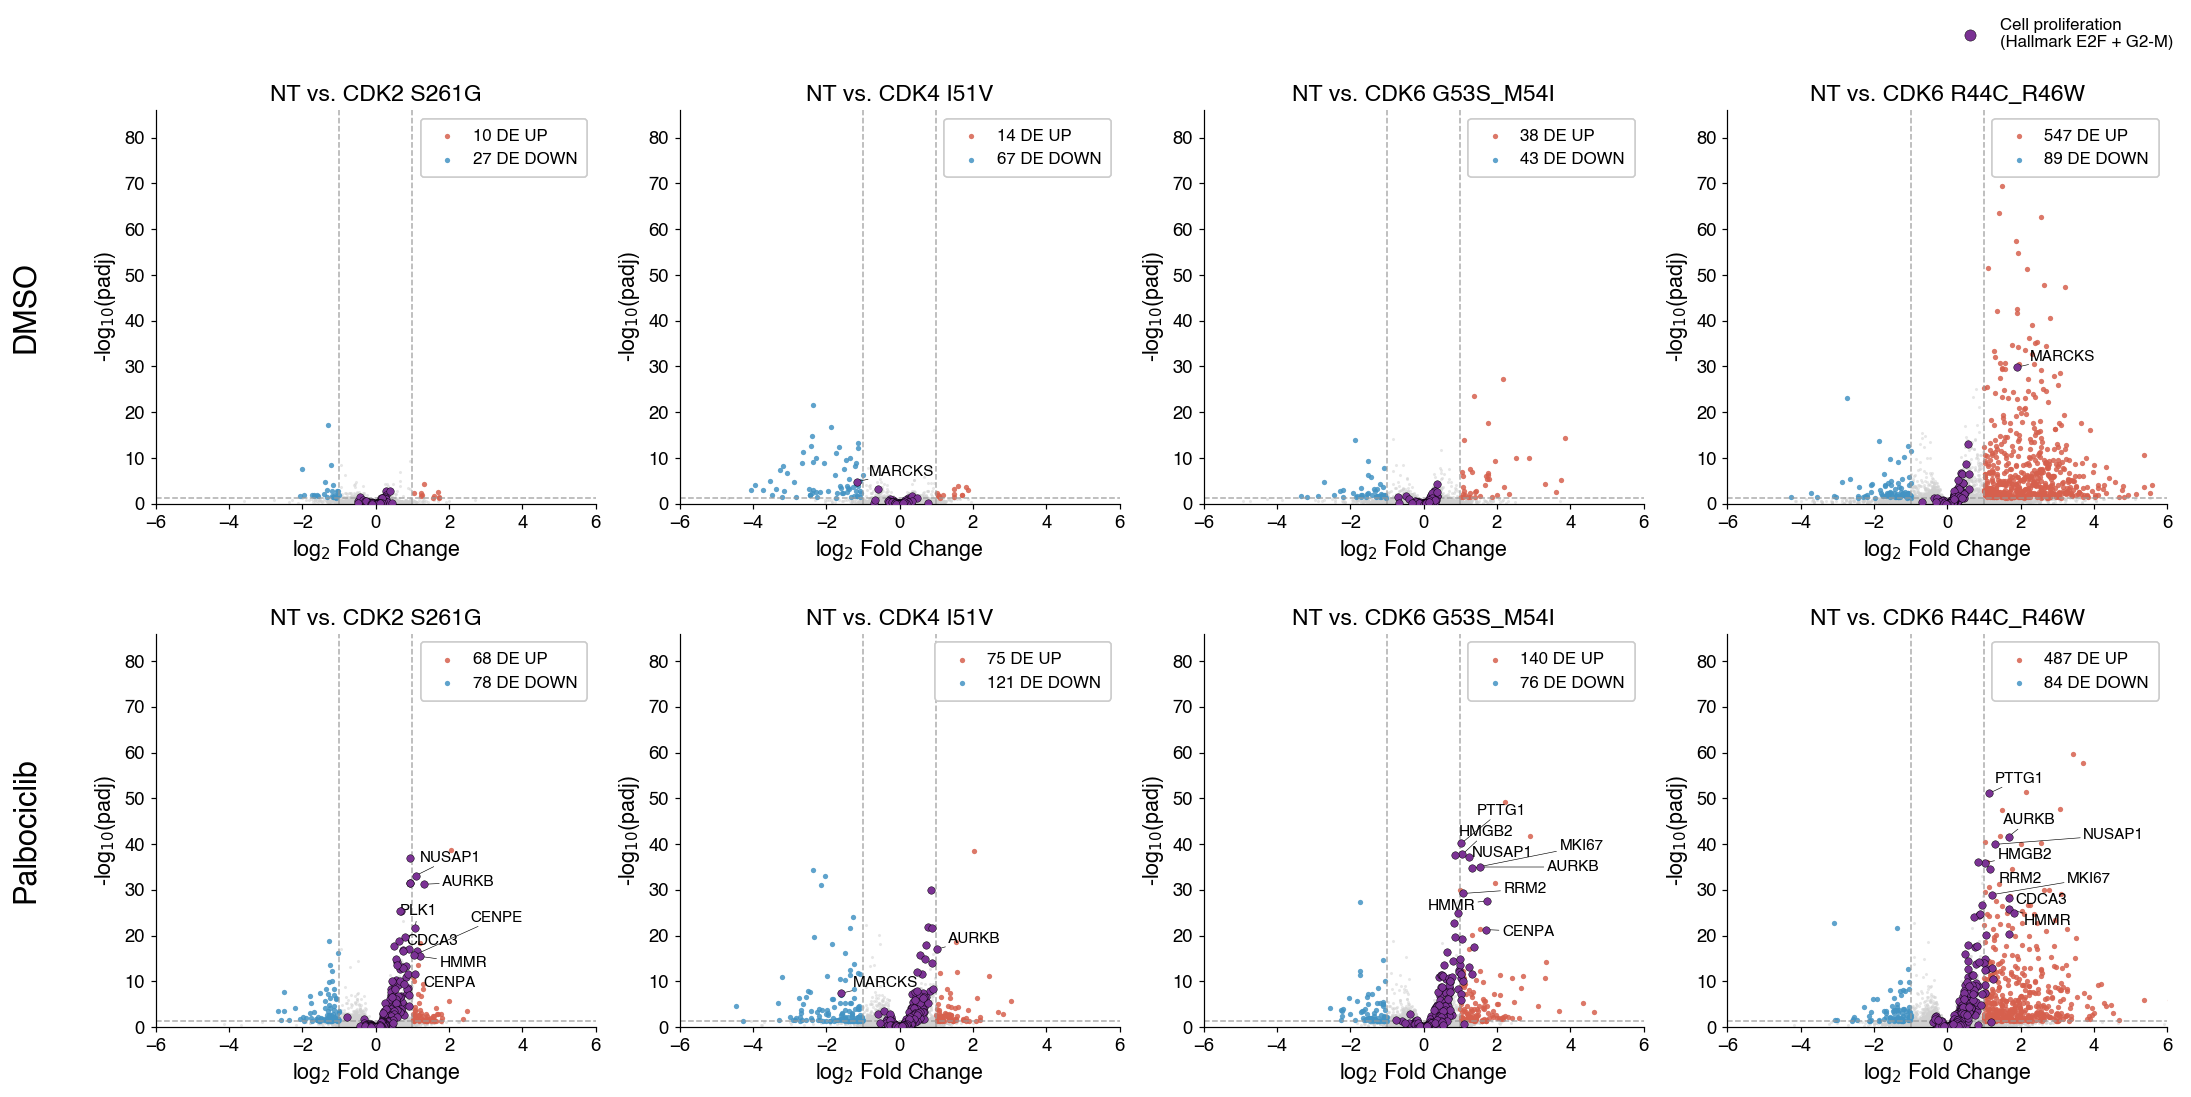

In [5]:
nrows, ncols = len(ROWS), len(CONTROL_FOR)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 5 * nrows), squeeze=False)

for r, (arm, row_label) in enumerate(ROWS):
    for c, (v, ctrl) in enumerate(CONTROL_FOR.items()):
        ax, rc = axes[r, c], results[(v, arm)]
        up   = (rc['padj'] < PADJ_THRESH) & (rc['log2FoldChange'] >  LFC_THRESH)
        down = (rc['padj'] < PADJ_THRESH) & (rc['log2FoldChange'] < -LFC_THRESH)
        ns   = ~(up | down)

        # base layer (muted so the cell-cycle highlights stand out)
        ax.scatter(rc.loc[ns, 'log2FoldChange'], rc.loc[ns, 'y'],
                   s=4, color=NS_COLOR, alpha=0.5, linewidths=0, rasterized=True)
        up_pts = ax.scatter(rc.loc[up, 'log2FoldChange'], rc.loc[up, 'y'],
                   s=12, color=UP_COLOR, alpha=0.85, linewidths=0, rasterized=True)
        down_pts = ax.scatter(rc.loc[down, 'log2FoldChange'], rc.loc[down, 'y'],
                   s=12, color=DOWN_COLOR, alpha=0.85, linewidths=0, rasterized=True)

        # cell-proliferation highlight (one group)
        cc = rc[rc['gene_name'].isin(PROLIF_GENES)]
        ax.scatter(cc['log2FoldChange'], cc['y'], s=24, color=PROLIF_COLOR,
                   edgecolors='black', linewidths=0.3, zorder=5,
                   label=(PROLIF_LABEL if (r, c) == (0, 0) else None))

        # label the most-significant cell-proliferation genes within the x range
        sig_cc = cc[(cc['padj'] < PADJ_THRESH) & (cc['log2FoldChange'].abs() > LFC_THRESH)
                    & (cc['log2FoldChange'].abs() <= X_LIM)].nsmallest(N_LABELS, 'padj')
        texts = [ax.text(row['log2FoldChange'], row['y'], row['gene_name'],
                         fontsize=FS_GENE, style='italic')
                 for _, row in sig_cc.iterrows()]

        ax.set_xlim(-X_LIM, X_LIM); ax.set_ylim(0, y_lim)
        for x in (LFC_THRESH, -LFC_THRESH):
            ax.axvline(x, color=THRESH_COLOR, lw=1.0, linestyle='--', alpha=0.8)
        ax.axhline(-np.log10(PADJ_THRESH), color=THRESH_COLOR, lw=1.0, linestyle='--', alpha=0.8)
        ax.spines[['top', 'right']].set_visible(False)
        ax.tick_params(labelsize=FS_TICK)
        ax.set_xlabel(r'log$_2$ Fold Change', fontsize=FS_AXIS)
        ax.set_ylabel(r'-log$_{10}$(padj)', fontsize=FS_AXIS)
        ax.set_title(f'NT vs. {pretty_label(v)}', fontsize=FS_TITLE)

        # DE counts, boxed top-right
        count_leg = ax.legend(handles=[up_pts, down_pts],
                              labels=[f'{int(up.sum())} DE UP', f'{int(down.sum())} DE DOWN'],
                              loc='upper right', fontsize=FS_LEGEND, frameon=True, framealpha=1,
                              edgecolor='#cccccc', fancybox=True, borderpad=0.6, handletextpad=0.5)
        ax.add_artist(count_leg)

        if HAS_ADJUSTTEXT and texts:
            adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='black', lw=0.4),
                        expand=(1.2, 1.4))

plt.tight_layout(rect=(0.04, 0, 1, 0.94), h_pad=3)   # room on the left for row labels, on top for the legend

# Cell-proliferation legend: figure-level, top-right corner above the panels
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc='upper right', bbox_to_anchor=(1.0, 1.0),
           fontsize=FS_LEGEND, frameon=False, markerscale=1.5)

# Row labels (DMSO / Palbociclib), centred on each row, left of the y-axis labels
for r, (_, row_label) in enumerate(ROWS):
    bb = axes[r, 0].get_position()
    fig.text(0.01, (bb.y0 + bb.y1) / 2, row_label, rotation=90, ha='left', va='center',
             fontsize=FS_ROW)

outpath = FIG_DIR / 'volcano_variant_vs_control'
plt.savefig(f'{outpath}.svg', dpi=300, bbox_inches='tight')
plt.savefig(f'{outpath}.png', dpi=300, bbox_inches='tight')
plt.show()
